In [1]:
print("Let's Start")

Let's Start


In [8]:
import html
import os
import re
from typing import List
import numpy as np
import requests
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

MODEL_NAME = "cardiffnlp/twitter-xlm-roberta-base-sentiment-multilingual"
YOUTUBE_API_KEY = os.getenv("YOUTUBE_API_KEY", "")
CONFIDENCE_THRESHOLD = 0.45

# Load model and reorder CardiffNLP head [0:Neg, 1:Neu, 2:Pos] -> [0:Neu, 1:Pos, 2:Neg]
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)

with torch.no_grad():
    reorder = [1, 2, 0]
    model.classifier.out_proj.weight.copy_(model.classifier.out_proj.weight[reorder])
    model.classifier.out_proj.bias.copy_(model.classifier.out_proj.bias[reorder])

model.config.id2label = {0: "Neutral", 1: "Positive", 2: "Negative"}
model.eval()

VIDEO_CACHE = {}


def clean_text(text: str) -> str:
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def extract_video_id(value: str) -> str:
    value = (value or "").strip()
    if re.fullmatch(r"[a-zA-Z0-9_-]{11}", value):
        return value
    patterns = [
        r"[?&]v=([a-zA-Z0-9_-]{11})",
        r"(?:youtu\.be/|youtube\.com/(?:shorts|embed|live)/)([a-zA-Z0-9_-]{11})",
    ]
    for pattern in patterns:
        match = re.search(pattern, value)
        if match:
            return match.group(1)
    return ""

def fetch_youtube_comments(video_id: str, max_comments: int = 150) -> List[str]:
    if not YOUTUBE_API_KEY:
        raise ValueError("YOUTUBE_API_KEY secret missing in Space Settings.")

    comments = []
    next_page_token = None
    url = "https://www.googleapis.com/youtube/v3/commentThreads"

    while len(comments) < max_comments:
        params = {
            "part": "snippet",
            "videoId": video_id,
            "maxResults": min(100, max_comments - len(comments)),
            "order": "relevance",
            "textFormat": "plainText",
            "key": YOUTUBE_API_KEY,
        }
        if next_page_token:
            params["pageToken"] = next_page_token

        resp = requests.get(url, params=params, timeout=10)
        if resp.status_code != 200:
            err_msg = resp.json().get("error", {}).get("message", "YouTube API error")
            raise ValueError(f"YouTube API error ({resp.status_code}): {err_msg}")

        data = resp.json()
        for item in data.get("items", []):
            raw = item["snippet"]["topLevelComment"]["snippet"]["textDisplay"]
            cleaned = clean_text(raw)
            if cleaned:
                comments.append(cleaned)

        next_page_token = data.get("nextPageToken")
        if not next_page_token:
            break

    return comments

def analyze_video(video_id: str, max_comments: int = 150):
    video_id = extract_video_id(video_id)
    if not video_id:
        return {"error": "Please provide a valid YouTube video URL or 11-character video ID."}

    max_comments = max(10, min(int(max_comments), 200))
    cache_key = f"{video_id}:{max_comments}"
    if cache_key in VIDEO_CACHE:
        return VIDEO_CACHE[cache_key]

    try:
        comments = fetch_youtube_comments(video_id, max_comments)
    except Exception as exc:
        return {"error": str(exc)}

    if not comments:
        return {"error": "No comments found for this video."}

    order = np.argsort([len(c) for c in comments])
    scored = [None] * len(comments)
    batch_size = 64
    device = next(model.parameters()).device

    for start in range(0, len(comments), batch_size):
        batch_idx = order[start : start + batch_size]
        batch_texts = [comments[i] for i in batch_idx]

        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt",
        ).to(device)

        with torch.inference_mode():
            if device.type == "cuda":
                with torch.amp.autocast("cuda", dtype=torch.float16):
                    logits = model(**inputs).logits
            else:
                logits = model(**inputs).logits

            probs = torch.softmax(logits.float(), dim=-1).cpu().numpy()

        for idx, text, p in zip(batch_idx, batch_texts, probs):
            pred_id = int(np.argmax(p))
            conf = float(p[pred_id])
            sentiment = "Neutral" if conf < CONFIDENCE_THRESHOLD else model.config.id2label[pred_id]
            scored[idx] = {
                "comment": text,
                "sentiment": sentiment,
                "confidence": round(conf, 4),
            }

    total = len(scored)
    counts = {"Positive": 0, "Negative": 0, "Neutral": 0}
    for item in scored:
        counts[item["sentiment"]] += 1

    percentages = {k: round((v / total) * 100, 2) for k, v in counts.items()}
    overall_mood = max(counts, key=counts.get)

    top_positive = sorted(
        [x for x in scored if x["sentiment"] == "Positive"],
        key=lambda x: x["confidence"],
        reverse=True,
    )
    top_negative = sorted(
        [x for x in scored if x["sentiment"] == "Negative"],
        key=lambda x: x["confidence"],
        reverse=True,
    )
    top_neutral = sorted(
        [x for x in scored if x["sentiment"] == "Neutral"],
        key=lambda x: x["confidence"],
        reverse=True,
    )
    response = {
        "video_id": video_id,
        "total_comments": total,
        "overall_mood": overall_mood,
        "counts": counts,
        "percentages": percentages,
        "top_positive": top_positive,
        "top_negative": top_negative,
        "top_neutral": top_neutral,
    }
    VIDEO_CACHE[cache_key] = response
    return response

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 24693.33it/s]


In [19]:
results = analyze_video(video_id='https://youtu.be/v-iOPqgNIT0?si=XizbjQLUvy_I9UaM')

In [20]:
results['counts']

{'Positive': 4, 'Negative': 3, 'Neutral': 11}

In [21]:
results['overall_mood']

'Neutral'

In [22]:
results['percentages']

{'Positive': 22.22, 'Negative': 16.67, 'Neutral': 61.11}

In [23]:
results['total_comments']

18

In [24]:
results['top_positive']

[{'comment': 'My subscription is worth it, good content Bro',
  'sentiment': 'Positive',
  'confidence': 0.9836},
 {'comment': 'Great content', 'sentiment': 'Positive', 'confidence': 0.9281},
 {'comment': 'When you mentioned cloned project and said not to clone projects and build something related to a problem so then I became happy bcz I have 5 different problems occuring everyday and one of them is a kind of problem which can be solved by RAG agent',
  'sentiment': 'Positive',
  'confidence': 0.6527},
 {'comment': 'sir i am a 11th student and wanred to create a future in ai and software field any suggestions or roadmap',
  'sentiment': 'Positive',
  'confidence': 0.4587}]

In [25]:
results['top_negative']

[{'comment': 'Commerce student please 😢',
  'sentiment': 'Negative',
  'confidence': 0.82},
 {'comment': 'Jo bhi padhta hu dead hojata hai😢',
  'sentiment': 'Negative',
  'confidence': 0.7036},
 {'comment': 'Kyun ghalat salat bata raha hy itna dum hy tuo apni live product dikha or apni live product ko diployment ker kay dikha cloud per ai ka choran khama kha ka mat bol bachon ko bilkul hi ghalat direction mat dai ?',
  'sentiment': 'Negative',
  'confidence': 0.5499}]

In [27]:
results['top_neutral']

[{'comment': 'Please make a video about SI (Super intelligence)',
  'sentiment': 'Neutral',
  'confidence': 0.9592},
 {'comment': 'Commerce student', 'sentiment': 'Neutral', 'confidence': 0.9375},
 {'comment': 'Bro video for commerce student',
  'sentiment': 'Neutral',
  'confidence': 0.9104},
 {'comment': "Sir, I just want to know that, I have a project in my resume, It's a console-based application that synchronizes clipboard data between two laptops over a local network without requiring an internet connection. Technically, it uses TCP socket programming, multithreading for concurrent sending and receiving, JSON for message serialization, Pydantic for data validation, and clipboard change detection. I wanted to ask whether this kind of project demonstrates valuable practical skills for a fresher's resume, or should I focus on building projects involving more industry-relevant technologies and architectures? What would you suggest improving to make it more valuable from an industry p

<Axes: >

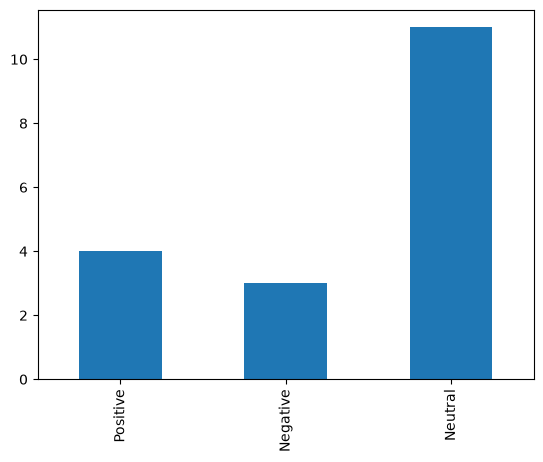

In [30]:
import pandas as pd

counts = pd.Series(results['counts'])
counts.plot(kind='bar')

<Axes: >

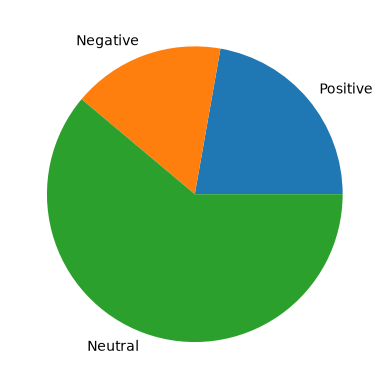

In [ ]:
per = pd.Series(results['percentages'])
per.plot(kind='pie')